# What is not a particle: a gallery of optical array probe artifacts

An optical array probe records the shadow a particle casts on a row of light detectors (diodes).
Not every shadow is a particle. Some are pieces of one particle that broke on the probe, some come
from the instrument itself, and some are real particles recorded in a way that misleads the size.
This notebook shows one picture of each kind, side by side, so you can recognise them.

### What you will learn

1. what nine common artifact families look like, each in one large panel;
2. the cause of each, in one line;
3. what the package's own functions return when given each picture, and which families the
   package has no detector for;
4. where each family is explained in depth.

### What data this uses

None from disk. Every image is **synthetic**, drawn in this notebook on a 48 x 48 pixel canvas
(the one random image uses a fixed seed, `seed=7`). No data is read or downloaded.

**Before this:** [05_triage_and_gallery](../1_getting_started/05_triage_and_gallery.ipynb) (Looking at particles: a contact sheet, a gallery, and the triage page), [01_start_here](../1_getting_started/01_start_here.ipynb) (explains how the images arise). **Related:** [13_shattering](13_shattering.ipynb). **Needs:** `pip install "arrayprobe[extra,zarr]"` (matplotlib, xarray).

This notebook reads files from the arrayprobe source repository, so run it from a clone of that repository; `pip install arrayprobe` alone does not include them.

The next cell checks that the notebook runs from the repository root, where the paths below start.

In [1]:
# Launch guard: the cells below reach scripts/ and tests/data/ relative to the repository root.
from pathlib import Path

if not (Path("scripts").is_dir() and Path("tests/data").is_dir()):
    raise RuntimeError(
        f"This notebook must run with the repository root as its working directory, not {Path.cwd()}. "
        "Jupyter starts a kernel in the notebook's own folder (examples/5_data_quality/), so run "
        "`%cd ../..` in a new cell, then run this cell again. "
        "Headless, from the repository root: python scripts/execute_example_notebooks.py --check <name>"
    )

import sys

if "examples" not in sys.path:  # shared helper modules (_style.py) sit in examples/
    sys.path.insert(0, "examples")

## 1. Drawing tools

Every picture is a small boolean array: `True` where a diode was in shadow. The rows are time
slices (the particle moving past the array), the columns are diodes (the figures below draw them
the other way round, time along the horizontal axis as in the OAP primer). A disc of diameter $d$
pixels centred on $(c_i, c_j)$ is the set of pixels with $(i-c_i)^2 + (j-c_j)^2 \le (d/2)^2$.

In [2]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

N = 48  # canvas: 48 slices x 48 diodes
ii, jj = np.mgrid[0:N, 0:N]


def disc(ci, cj, d):
    return (ii - ci) ** 2 + (jj - cj) ** 2 <= (d / 2) ** 2


def ring(ci, cj, d_out, d_in):
    return disc(ci, cj, d_out) & ~disc(ci, cj, d_in)


def blank():
    return np.zeros((N, N), dtype=bool)

## 2. The nine pictures

Each image is built to show one family from the artifact inventory this project keeps. The
drawings are schematic: sizes and positions are chosen to make the feature visible, not copied
from any real record.

In [3]:
rng = np.random.default_rng(seed=7)
art = {}

img = blank()                                   # shattering: many small fragments together
for ci, cj, d in [(8, 10, 4), (14, 30, 3), (22, 18, 5), (30, 36, 3), (36, 9, 4), (40, 26, 3)]:
    img |= disc(ci, cj, d)
art["Shattered fragments"] = img

img = disc(24, 20, 14)                          # stuck diode: one column dark in every slice
img[:, 34] = True
art["Stuck diode"] = img

art["Hollow ring (out of focus)"] = ring(24, 24, 26, 14)

art["Touching the edge"] = disc(24, 6, 22)      # centre near diode 6: left part cut off

art["Image in pieces"] = disc(24, 24, 20) & ~((jj >= 22) & (jj <= 26))  # gap through a drop

img = disc(30, 14, 12)                          # drop plus two far-off stray pixels
img[6, 40] = True
img[7, 41] = True
art["Drop plus stray pixels"] = img

art["Two particles in one frame"] = disc(16, 14, 12) | disc(32, 32, 14)

img = blank()                                   # streak: one diode lit for a run of slices, not the full height
img[10:38, 23] = True
art["Streak"] = img

art["Sparse noise"] = rng.random((N, N)) < 0.012  # a few scattered pixels

print(f"{len(art)} pictures, each {N} x {N} pixels")

9 pictures, each 48 x 48 pixels


## 3. The gallery

Nine panels in three one-row figures, grouped by what goes wrong: images that are cut, split or
merged; extra pixels and stuck diodes; break-up, focus and noise. Each title gives the plain name and,
below it, the cause in one line. All panels share one scale: the bar at the bottom left is 10 pixels,
which is 100 µm at 10 µm per pixel (an assumption; pixel size differs between probes, so rescale for
yours). The
faint grid marks single pixels.

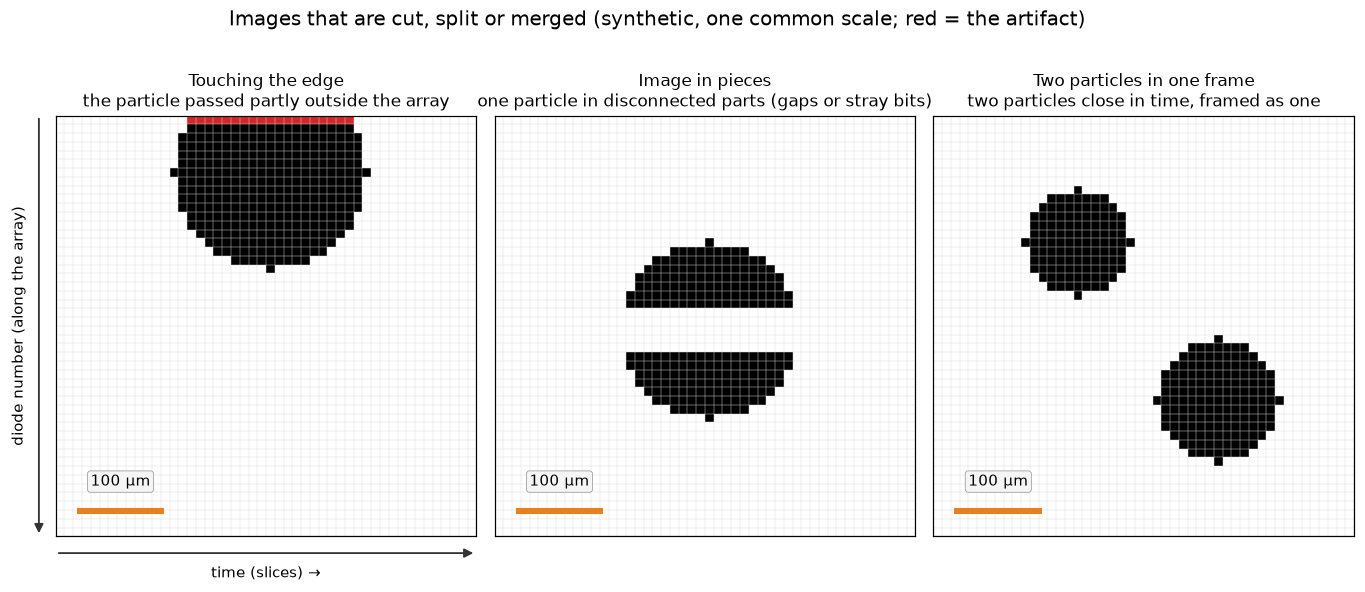

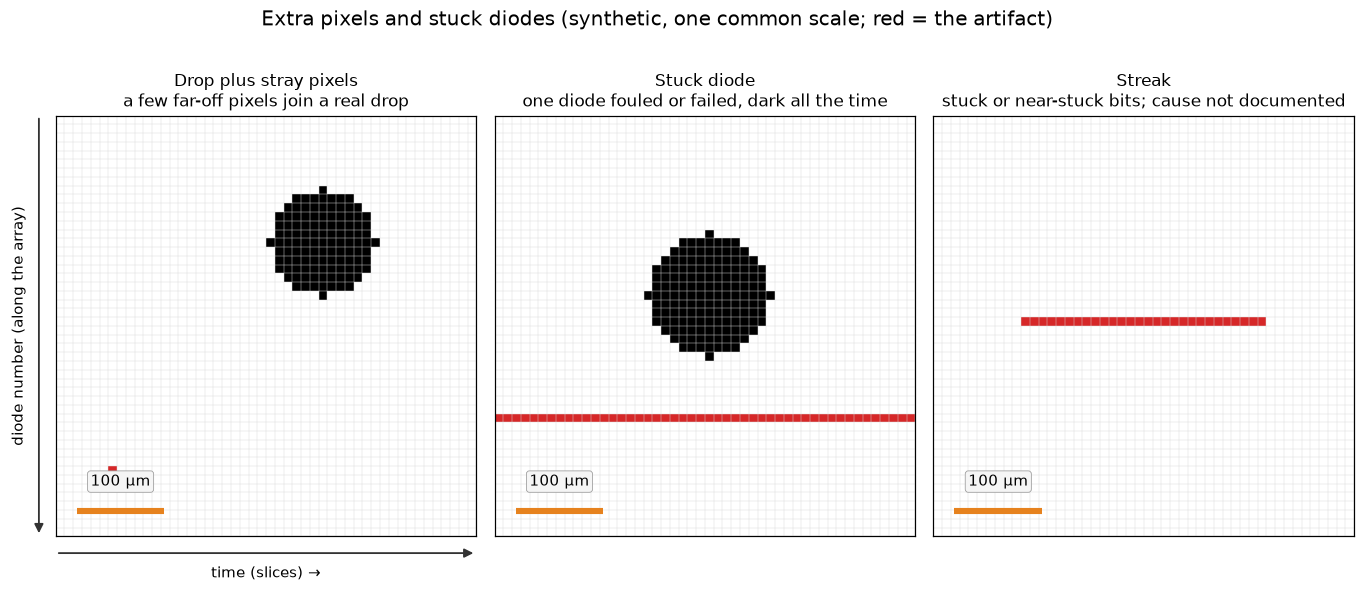

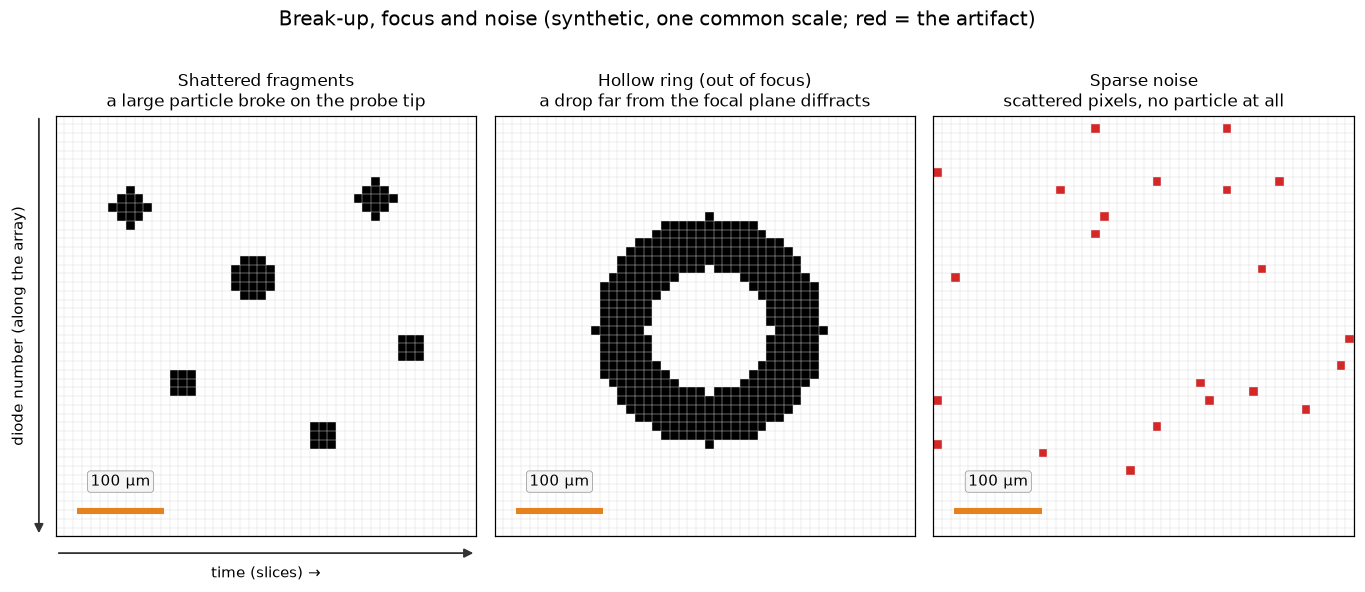

In [4]:
cause = {
    "Shattered fragments": "a large particle broke on the probe tip",
    "Stuck diode": "one diode fouled or failed, dark all the time",
    "Hollow ring (out of focus)": "a drop far from the focal plane diffracts",
    "Touching the edge": "the particle passed partly outside the array",
    "Image in pieces": "one particle in disconnected parts (gaps or stray bits)",
    "Drop plus stray pixels": "a few far-off pixels join a real drop",
    "Two particles in one frame": "two particles close in time, framed as one",
    "Streak": "stuck or near-stuck bits; cause not documented",
    "Sparse noise": "scattered pixels, no particle at all",
}
import sys
sys.path.insert(0, ".")
import _style
_style.apply()

groups = {
    "gallery_1_cut_split_merged": ("Images that are cut, split or merged",
        ["Touching the edge", "Image in pieces", "Two particles in one frame"]),
    "gallery_2_extra_pixels_stuck_diodes": ("Extra pixels and stuck diodes",
        ["Drop plus stray pixels", "Stuck diode", "Streak"]),
    "gallery_3_breakup_focus_noise": ("Break-up, focus and noise",
        ["Shattered fragments", "Hollow ring (out of focus)", "Sparse noise"]),
}
red = {"Drop plus stray pixels": art["Drop plus stray pixels"] & ~disc(30, 14, 12),  # the artifact, in red
       "Stuck diode": art["Stuck diode"] & ~disc(24, 20, 14), "Streak": art["Streak"],
       "Touching the edge": art["Touching the edge"] & (jj == 0), "Sparse noise": art["Sparse noise"]}
for fname, (heading, members) in groups.items():
    fig, axes = plt.subplots(1, 3, figsize=(13, 5.8))
    for k, (ax, name) in enumerate(zip(axes, members, strict=True)):
        _style.pixels(ax, art[name], red=red.get(name), um_per_px=10.0,
                      title=f"{name}\n{cause[name]}", time_x=True, key=(k == 0))
        ax.title.set_fontsize(11)
    fig.suptitle(f"{heading} (synthetic, one common scale; red = the artifact)")
    fig.tight_layout(rect=(0.04, 0.03, 1, 1))
    fig.savefig(f"examples/figures/artifact_{fname}.png", dpi=110)
    plt.show()

How a streak differs from a stuck diode in what the data show: a stuck diode is dark across the whole
record (the one measured case is 99.68 % of 929 slices), so it draws a line across the full time
extent of the frame, while a streak is a line over only part of the record, starting and ending
inside the frame. The project's artifact notes do not state this distinction themselves: they describe a stuck diode
as reading dark continuously (and notes the file mask misses short episodes), and a streak only as
"stuck or near-stuck bits", cause not documented, so the partial-versus-whole contrast is how the
two synthetic panels are drawn, not a documented rule.

Look for the feature, not the size. Shattered fragments are many small shapes in one frame; a
stuck diode is one dark line running the full time extent of the frame, through whatever else is
there; a streak is a one-pixel line along time that starts and ends inside the frame, with nothing
else around it; a hollow ring has a lit centre; a drop touching the edge is cut flat at the array side; stray pixels sit
far from an otherwise round drop; two particles in one frame are two complete shapes.

### Who addresses each artifact, and how

Each cell ends with the file and line it comes from. *Unknown* means no source was found in the repository for
that cell, not that the answer is no. Other packages are named only where the repository cites one
(only Process2D appears, for shattering). "Reaccepted" counts the particles a fix hands back that a
default step had rejected; the repository has **no measured reaccept count for any artifact**, so
that column says *not measured* and the nearest measured effect sits beside it.

**What "on by default" means here** (`docs/06-configuration.md`, sections "Corrections engine 3.5 applies by default" and "`[enhancements]` means the same thing to both drivers"). The batch driver's *protective set* (particle-time glitch, int8 time and
true-airspeed grid fixes) is the only enhancement list it runs by default, and it contains none of the corrections in this
table. Two corrections are nevertheless on by default in the engine-3.5 driver, outside that set: the stray-pixel correction
(`--stray-pixel off` to skip) and the bin-table correction (a 2D-S falling to the HVPS table). Every other correction
named here is opt-in per run, or on only with `all = true`.

| Artifact | UIOOPS (upstream) | SODA-2 | How: reject / correct / reaccept | This package; on by default? | Particles reaccepted; nearest measured effect |
|---|---|---|---|---|---|
| Shattered fragments | yes: `sizeDist` shattering block (reported to the UIOOPS developers) | interarrival fit exists (`fit_poisson.py:3`); how it rejects: unknown | reject by arrival-time gap; reaccept of big particles caught in a burst (`sizedist_tables.py:563`, `:587`); upstream scans only the first event in two of three paths (`docs/07-findings.md:46-51`) | ports the block; `reaccept_every_event_fix` default OFF; Process2D-derived `field2006_shatter` opt-in (`docs/23-enhancements-by-engine.md:54`) | not measured on shipped data |
| Stuck diode | yes: two-pass `find_shadow_diodes` mask; misses short episodes (reported to the UIOOPS developers) | yes: `fixstuckbits` (`fixstuckbits.py:3`, `.pro:8-29`) | correct: diodes masked or bits cleared; not a per-image reject | ports both; missing mask made loud (`enhancements_uiops/docs/CORRECTIONS.md`, "Design: a missing or misnamed shadow-diode mask stops being silent"); UIOOPS mask: off by default, `--diode-corrected` applies it to two 2016 field-campaign files only (`run_flight.py:3277`); SODA-2 `fixstuckbits`: off unless `stuckbits=1` (`update_op.py:22`); our guard `no_stuck_diode_fix`: on by default, inert unless `stuckbits=1` (`docs/05-enhancements.md`, "SODA-2 corrections") | not measured. One diode dark in 99.68 % of 929 slices (reported to the UIOOPS developers) |
| Hollow ring | yes: `is_it_hollow`, reject `'h'`/`'H'`; the archived-product reproduction runs with `rej_hollow=0` so it never fires there | related, not the same test: depth-of-field reject `binary_dof` when `dofreject=3` (`binary_dof.py:3-8`) | reject or correct size (Korolev factor computed, never applied upstream; reported to the UIOOPS developers) | `wide_hollow_fix`, `outoffocus` enhancements; both off by default for every probe, opt-in per run; `outoffocus` is excluded even from `all = true` on engine 3.5 (`registry.py:736`) | not measured on shipped data; v3.5's hollow rule runs unconditionally under its shipped default |
| Touching the edge | yes: `touching_edge` flag; reject `'t'` unreachable in v3.1.4 (`calculate_reject_unified.m:269,272`) | yes: `edgetouch` flag (`docs/21-api-soda2.md:596`) | flag only; no size reconstruction found | records the flag; `spot_edge_fix`, `partial_image_habit` enhancements (`docs/23-enhancements-by-engine.md:63`); both off by default for every probe, opt-in per run | not measured |
| Image in pieces | rejects split images (`'s'`, `arrayprobe_uiops/reject.py:373-432`); grouping: none found | unknown | reject upstream; group in the review tool (`stray_pixel.py:12`, gap 8 diodes) | grouping in the review tool only, not in processing; default: not applicable | not measured |
| Drop plus stray pixels | no: identified by eye (`stray_pixel.py:4-6`) | unknown | correct: strays removed, drop re-sized and re-tested | `remove_stray_pixels`: on by default in the engine-3.5 batch driver for every probe, the archived-product lineage included (`--stray-pixel off` to skip; `run_flight.py:1126-1147`); the library function default is off (`stray_pixel.py:9`, `arrayprobe_uiops/imgproc.py:571`) | not measured. One flight: 333 of 15,189 s change, Z -0.14 dB overall (measured on one ARM flight) |
| Two particles in one frame | reported to the original developers only (upstream feedback list) | unknown | none | no detector | not measured; one confirmed instance |
| Streak | none found | yes: `streak` flag when the busiest diode exceeds 3 times the mean (`processbuffer_tail.py:213`) | flag; in the demo flight a one-diode streak is caught only incidentally, by aspect ratio `'a'` (`make_demo_flight.py:486-488`) | SODA-2 routine ported; default: not applicable (no streak correction found; the flag is only recorded) | not measured |
| Sparse noise | opt-in `iQC` denoise in v3.5 | unknown | correct (denoise), opt-in | review-tool label; `iQC` default off upstream | not measured |

## 4. What the package returns for each picture

Two of the package's per-image functions are run on every picture, unchanged:

- `is_it_hollow`, the hollow test, whose answer the engine passes into the reject step;
- `calculate_reject_unified`, the UIOOPS engine's accept/reject test, given that answer: its reject
  code and its `touching_edge` flag (`'t'` touching, `'0'` not). The habit letter it also takes is
  a placeholder (`"S"`) here, since only the hollow branch reads it.

The reject codes, as the code assigns them: `'0'` accepted; `'s'` the image is split into parts;
`'a'` aspect ratio outside the limit; `'t'` touching the edge with a large aspect ratio; `'p'`
too little of its bounding box is shadowed; `'A'` it fills most of the frame; `'H'` hollow,
accepted with an out-of-focus size factor; `'h'` and `'u'` hollow but the hole could not be
used.
- `remove_stray_pixels`, the stray-pixel correction: how many pixels it would remove.

The output is whatever the functions return. Families detected from something other than one image
(arrival times, a whole file) are covered in the next section.

In [5]:
from arrayprobe_uiops.reject import calculate_reject_unified, is_it_hollow
from arrayprobe_uiops.reject_core import RejectConfig
from arrayprobe_uiops.stray_pixel import remove_stray_pixels

config = RejectConfig()
print(f"{'picture':30s} {'reject':>6s} {'hollow':>6s} {'touch':>6s} {'stray removed':>14s}")
results = {}
for name, img in art.items():
    hollow = int(is_it_hollow(img, img.shape[0])[0])  # the hollow test, run first
    r = calculate_reject_unified(img, "S", hollow, config)
    _, rec = remove_stray_pixels(img.astype(np.uint8))
    results[name] = (r, rec)
    print(f"{name:30s} {r.reject_status!r:>6} {int(r.is_hollow):>6d} "
          f"{r.touching_edge!r:>6} {rec['removed']:>8d} px")

picture                        reject hollow  touch  stray removed
Shattered fragments               's'      0    '0'        0 px
Stuck diode                       'p'      0    '0'        0 px
Hollow ring (out of focus)        'H'      1    '0'        0 px
Touching the edge                 '0'      0    't'        0 px
Image in pieces                   '0'      0    '0'        0 px
Drop plus stray pixels            's'      0    '0'        2 px
Two particles in one frame        's'      0    '0'        0 px
Streak                            'a'      0    '0'        0 px
Sparse noise                      's'      0    '0'        0 px


Read each row against its picture. Where a function flags the family it was built for, the row
shows it; where a row shows nothing, the package has no single-image detector for that family, or
catches it another way, as the next table says.

### The same results as a labelled dataset and a table

The per-picture results above, collected in an `xarray.Dataset` whose variables carry `units`
attributes, so each number says what it is measured in.

In [6]:
import pandas as pd
import xarray as xr

names = list(art)
def var(name, values, units):
    return xr.DataArray(values, dims="picture", coords={"picture": names},
                        attrs={"units": units}, name=name)

ds = xr.merge([
    var("shadowed_pixels", [int(art[n].sum()) for n in names], "pixel"),
    var("stray_removed", [results[n][1]["removed"] for n in names], "pixel"),
    var("hollow_flag", [int(results[n][0].is_hollow) for n in names], "1"),
])
ds.attrs["title"] = "Synthetic artifact pictures, package results"
ds

<xarray.Dataset> Size: 1kB
Dimensions:          (picture: 9)
Coordinates:
  * picture          (picture) <U26 936B 'Shattered fragments' ... 'Sparse no...
Data variables:
    shadowed_pixels  (picture) int64 72B 74 197 380 322 220 115 262 28 22
    stray_removed    (picture) int64 72B 0 0 0 0 0 2 0 0 0
    hollow_flag      (picture) int64 72B 0 0 1 0 0 0 0 0 0
Attributes:
    units:    pixel
    title:    Synthetic artifact pictures, package results

The same numbers as a table, with the units in the column names.

In [7]:
df = ds.to_dataframe()
df.columns = [f"{c} ({ds[c].attrs['units']})" for c in df.columns]
df["reject code"] = [results[n][0].reject_status for n in names]
df["touching edge"] = [results[n][0].touching_edge for n in names]
df

,shadowed_pixels (pixel),stray_removed (pixel),hollow_flag (1),reject code,touching edge
picture,,,,,
Shattered fragments,74,0,0,s,0
Stuck diode,197,0,0,p,0
Hollow ring (out of focus),380,0,1,H,0
Touching the edge,322,0,0,0,t
Image in pieces,220,0,0,0,0
Drop plus stray pixels,115,2,0,s,0
Two particles in one frame,262,0,0,s,0
Streak,28,0,0,a,0
Sparse noise,22,0,0,s,0


How much of the frame each picture shades, for scale: a stuck diode shades a full line along time, noise
only a handful of pixels.

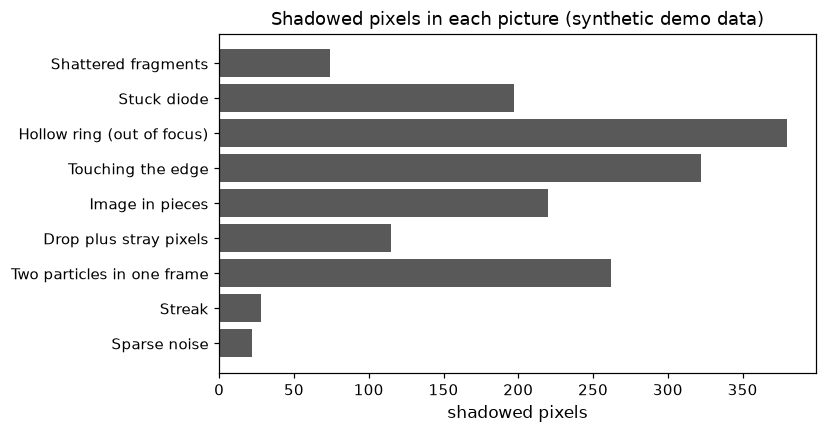

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(names, ds["shadowed_pixels"].values, color="0.35")
ax.invert_yaxis()
ax.set_xlabel("shadowed pixels")
ax.tick_params(labelsize=10)
ax.set_title("Shadowed pixels in each picture (synthetic demo data)")
fig.savefig("examples/figures/artifact_coverage.png", dpi=110, bbox_inches="tight")
plt.show()

*Figure 4. The number of shadowed pixels in each synthetic picture of the gallery, one bar per picture.*


The long bars are pictures with a large particle; the short ones are the pictures whose defect is
small in area but can still change a size or a count.

## 5. Each family in short

"How often" quotes only figures this project has measured, with their scope; otherwise it says
*not measured yet*. "On by default" refers to the engine-3.5 batch driver: its protective set, plus the stray-pixel and bin-table corrections; every other correction is opt-in (`docs/06-configuration.md`, sections "Corrections engine 3.5 applies by default" and "`[enhancements]` means the same thing to both drivers").

| Family | Cause in plain words | What the package does | How often | In depth |
|---|---|---|---|---|
| Shattered fragments | a large particle breaks on the probe tip; fragments arrive almost together | rejects particles whose arrival-time gap is below a threshold (from arrival times, not the image); on when a threshold is given | not measured yet on data this package ships | [13_shattering.ipynb](13_shattering.ipynb) |
| Stuck diode | a diode is fouled or failed and stays dark | a per-file diode mask built in two passes; not a per-image test | one diode dark in 99.68 % of 929 slices, in one particle image | [17_stuck_diodes.ipynb](17_stuck_diodes.ipynb) |
| Hollow ring | a drop far from focus images as a ring | hollow test in the reject step; out-of-focus size correction as an opt-in enhancement | not measured yet on data this package ships; the engine's experimental hollow rule runs under its shipped default | [15_hollow_rings.ipynb](15_hollow_rings.ipynb) |
| Touching the edge | the particle passed partly outside the array | `touching_edge` recorded per particle; no size reconstruction | not measured yet | [18_edge_touching.ipynb](18_edge_touching.ipynb) |
| Image in pieces | one particle in disconnected parts (gaps or stray bits) | pieces within 8 empty diodes grouped as one, in the review tool | not measured yet | [14_stray_pixels.ipynb](14_stray_pixels.ipynb) |
| Drop plus stray pixels | far-off pixels make a small drop look large | stray pixels removed and the drop re-sized; on by default (`--stray-pixel off` to skip) | on one flight, 333 of 15,189 seconds change; particle number +0.0004 %, liquid water +0.003 % | [14_stray_pixels.ipynb](14_stray_pixels.ipynb) |
| Two particles in one frame | two close particles framed as one | no detector in the package | one confirmed instance | [19_two_particles.ipynb](19_two_particles.ipynb) |
| Streak | a column of stuck or near-stuck bits; cause not documented further | the SODA-2 engine's streak routine; no detector in the UIOOPS engine | not measured yet | [17_stuck_diodes.ipynb](17_stuck_diodes.ipynb) |
| Sparse noise | scattered pixels, no particle | an opt-in de-noising option in the UIOOPS engine (off by default); a label in the review tool | not measured yet | [17_stuck_diodes.ipynb](17_stuck_diodes.ipynb) |

## What to try next

- Move the drop in *Touching the edge* inward (`disc(24, 6, 22)` to `disc(24, 16, 22)`) and rerun
  section 4: watch the `touch` column.
- Move a stray pixel in *Drop plus stray pixels* to within 8 empty diodes of the drop and see
  whether `remove_stray_pixels` still removes it.
- Change `seed=7` or the noise level `0.012` and see how the reject code for *Sparse noise* moves.
- Next: [13_shattering.ipynb](13_shattering.ipynb) takes the first family, shattered fragments, in depth;
  the other families follow in [14_stray_pixels.ipynb](14_stray_pixels.ipynb)
  and the notebooks linked in the table above. For the instrument itself, see
  [Start here](../1_getting_started/01_start_here.ipynb).